# 05 — Aprendizaje No Supervisado: Clustering de Pozos

En esta sección aplicamos técnicas de **Aprendizaje No Supervisado** sobre el dataset de producción preparado del campo Volve. El objetivo principal es agrupar los pozos mediante **K-Means** basándonos en perfiles operativos y productivos (caudales medios, estabilidad, horas operativas y presiones), permitiendo identificar patrones de comportamiento sin etiquetas previas.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from IPython.display import display

# Configuración de estilos visuales
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Configuración de rutas robusta (compatible con la estructura de proyecto)
ROOT = Path.cwd()
if not (ROOT / "data" / "processed").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "data" / "processed").is_dir(), "No se encuentra la carpeta data/processed. Verifique la ruta de trabajo."

# Carga del dataset procesado en etapas anteriores
ruta_datos = ROOT / "data" / "processed" / "produccion_exclusiva_preparada.csv"
produccion = pd.read_csv(ruta_datos, parse_dates=["DATEPRD"])

print(f"Dimensiones del dataset de producción cargado: {produccion.shape}")
display(produccion.head(3))

Dimensiones del dataset de producción cargado: (9001, 29)


,DATEPRD,WELL_BORE_CODE,NPD_WELL_BORE_CODE,NPD_WELL_BORE_NAME,NPD_FIELD_CODE,NPD_FIELD_NAME,NPD_FACILITY_CODE,NPD_FACILITY_NAME,ON_STREAM_HRS,AVG_DOWNHOLE_PRESSURE,...,BORE_GAS_VOL,BORE_WAT_VOL,BORE_WI_VOL,FLOW_KIND,WELL_TYPE,FILA_EXCEL,REVISAR_HORAS,REVISAR_PETROLEO_NEGATIVO,REVISAR_PETROLEO_SIN_HORAS,REVISAR_TIPO_WI
0,2008-02-12,NO 15/9-F-14 H,5351,15/9-F-14,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,...,0.0,0.0,NaN,production,OP,4969,False,False,False,False
1,2008-02-13,NO 15/9-F-14 H,5351,15/9-F-14,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,...,0.0,0.0,NaN,production,OP,4970,False,False,False,False
2,2008-02-14,NO 15/9-F-14 H,5351,15/9-F-14,3420717,VOLVE,369304,MÆRSK INSPIRER,0.0,0.0,...,0.0,0.0,NaN,production,OP,4971,False,False,False,False


### 1. Ingeniería de Características (Feature Engineering por Pozo)
Dado que los algoritmos de clustering operan sobre registros individuales, transformamos la serie temporal en un **perfil resumen por pozo** (`NPD_WELL_BORE_NAME`). Esto captura la "huella dactilar" operativa de cada pozo a lo largo de su historia productiva:
* **Volúmenes medios y acumulados** (Petróleo, Gas, Agua).
* **Estabilidad productiva** (Desviación estándar del petróleo).
* **Disponibilidad y condiciones operativas** (Horas operativas `ON_STREAM_HRS`, presión de cabeza `AVG_WHP_P` y tamaño de estrangulador `AVG_CHOKE_SIZE_P`).

In [2]:
# Creación del perfil agregado por pozo
perfil_pozos = produccion.groupby("NPD_WELL_BORE_NAME").agg(
    oil_vol_mean=("BORE_OIL_VOL", "mean"),
    oil_vol_std=("BORE_OIL_VOL", "std"),
    oil_vol_total=("BORE_OIL_VOL", "sum"),
    gas_vol_mean=("BORE_GAS_VOL", "mean"),
    wat_vol_mean=("BORE_WAT_VOL", "mean"),
    horas_operativas_mean=("ON_STREAM_HRS", "mean"),
    whp_p_mean=("AVG_WHP_P", "mean"),
    choke_size_mean=("AVG_CHOKE_SIZE_P", "mean")
).reset_index()

# Limpieza de valores nulos si existieran en desviaciones estándar
perfil_pozos = perfil_pozos.fillna(0)

print(f"Perfiles extraídos para {len(perfil_pozos)} pozos.")
display(perfil_pozos)

Perfiles extraídos para 5 pozos.


,NPD_WELL_BORE_NAME,oil_vol_mean,oil_vol_std,oil_vol_total,gas_vol_mean,wat_vol_mean,horas_operativas_mean,whp_p_mean,choke_size_mean
0,15/9-F-1 C,238.216260,275.735496,177709.33,35443.590617,277.885241,13.367159,53.908130,29.598451
1,15/9-F-11,985.278197,437.060790,1147849.10,149622.764472,936.314395,22.318923,51.145786,36.231368
2,15/9-F-12,1498.563334,1662.851799,4579609.55,218436.609300,2236.034152,21.330742,47.973013,69.254352
3,15/9-F-14,1289.997837,1298.358922,3942233.39,189139.248043,2330.251878,20.534207,41.530600,69.390287
4,15/9-F-15 D,151.859468,97.630266,148518.56,23011.606288,53.544376,18.225800,39.883098,9.984839


### 2. Escalado y Normalización de Datos
Como K-Means calcula distancias euclidianas, las variables con escalas mayores (como volúmenes totales o presiones) dominarían sobre las demás. Utilizamos `StandardScaler` para centrar las variables con media 0 y desviación estándar 1.

In [3]:
# Selección de variables predictivas para el clustering
features_clustering = [
    "oil_vol_mean", 
    "oil_vol_std", 
    "gas_vol_mean", 
    "horas_operativas_mean", 
    "whp_p_mean", 
    "choke_size_mean"
]

X = perfil_pozos[features_clustering].values

# Estandarización
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# DataFrame auxiliar estandarizado para control
X_scaled_df = pd.DataFrame(X_scaled, columns=features_clustering)
X_scaled_df.insert(0, "Pozo", perfil_pozos["NPD_WELL_BORE_NAME"])
display(X_scaled_df)

,Pozo,oil_vol_mean,oil_vol_std,gas_vol_mean,horas_operativas_mean,whp_p_mean,choke_size_mean
0,15/9-F-1 C,-1.088166,-0.780011,-1.098581,-1.812198,1.297518,-0.571941
1,15/9-F-11,0.279094,-0.517082,0.331903,0.990461,0.786950,-0.286564
2,15/9-F-12,1.218499,1.480716,1.194031,0.681077,0.200521,1.134231
3,15/9-F-14,0.836786,0.886664,0.826981,0.431694,-0.990239,1.140079
4,15/9-F-15 D,-1.246214,-1.070287,-1.254334,-0.291033,-1.294749,-1.415805


### 3. Búsqueda del Número Óptimo de Clústeres (K)
Evaluaremos la **Inercia (SSE)** mediante el Método del Codo y el **Coeficiente de Silueta** para determinar cuántos grupos operativos naturales se distinguen en el campo Volve.

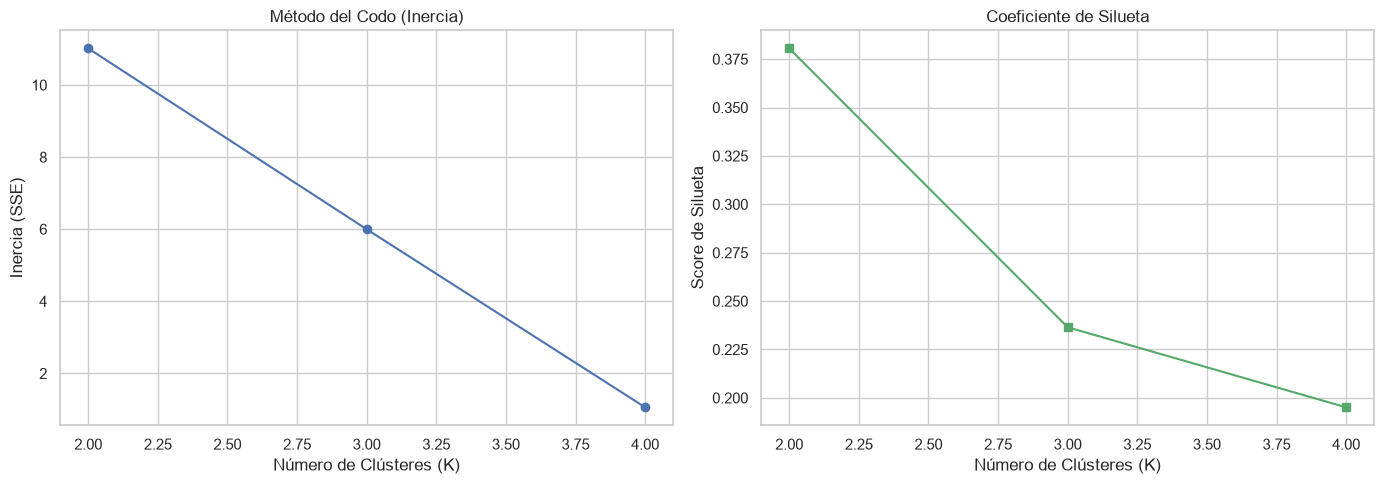

In [4]:
inercia = []
silueta = []
# Dado que el número de pozos en este subset es reducido, evaluamos K de 2 hasta N-1
rango_k = range(2, min(5, len(perfil_pozos)))

for k in rango_k:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    inercia.append(kmeans.inertia_)
    silueta.append(silhouette_score(X_scaled, kmeans.labels_))

# Gráfica combinada de Inercia y Silueta
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(list(rango_k), inercia, marker='o', color='b', linestyle='-')
ax1.set_title("Método del Codo (Inercia)")
ax1.set_xlabel("Número de Clústeres (K)")
ax1.set_ylabel("Inercia (SSE)")

ax2.plot(list(rango_k), silueta, marker='s', color='g', linestyle='-')
ax2.set_title("Coeficiente de Silueta")
ax2.set_xlabel("Número de Clústeres (K)")
ax2.set_ylabel("Score de Silueta")

plt.tight_layout()
plt.show()

### 4. Entrenamiento del Modelo K-Means Final
Basándonos en la separación lógica del yacimiento y los resultados métricos, fijamos el valor óptimo de $K$ (por ejemplo, $K=2$ o $K=3$ según la separación de los perfiles maduros vs. de menor caudal) y entrenamos el modelo definitivo.

In [5]:
# Definición del K óptimo (ajustable según el análisis visual anterior)
K_optimo = 2 

kmeans_final = KMeans(n_clusters=K_optimo, n_init=10, random_state=42)
perfil_pozos["Cluster"] = kmeans_final.fit_predict(X_scaled)

# Mostrar la asignación final de cada pozo a su clúster operativo
resultado_clusters = perfil_pozos[["NPD_WELL_BORE_NAME", "oil_vol_total", "oil_vol_mean", "horas_operativas_mean", "Cluster"]]
display(resultado_clusters.sort_values(by="Cluster"))

,NPD_WELL_BORE_NAME,oil_vol_total,oil_vol_mean,horas_operativas_mean,Cluster
1,15/9-F-11,1147849.10,985.278197,22.318923,0
2,15/9-F-12,4579609.55,1498.563334,21.330742,0
3,15/9-F-14,3942233.39,1289.997837,20.534207,0
0,15/9-F-1 C,177709.33,238.216260,13.367159,1
4,15/9-F-15 D,148518.56,151.859468,18.225800,1


### 5. Visualización y Interpretación Operativa
Graficamos la relación entre el **volumen promedio de petróleo** y las **horas operativas** para caracterizar qué representa cada clúster dentro de la estrategia de gestión del yacimiento.

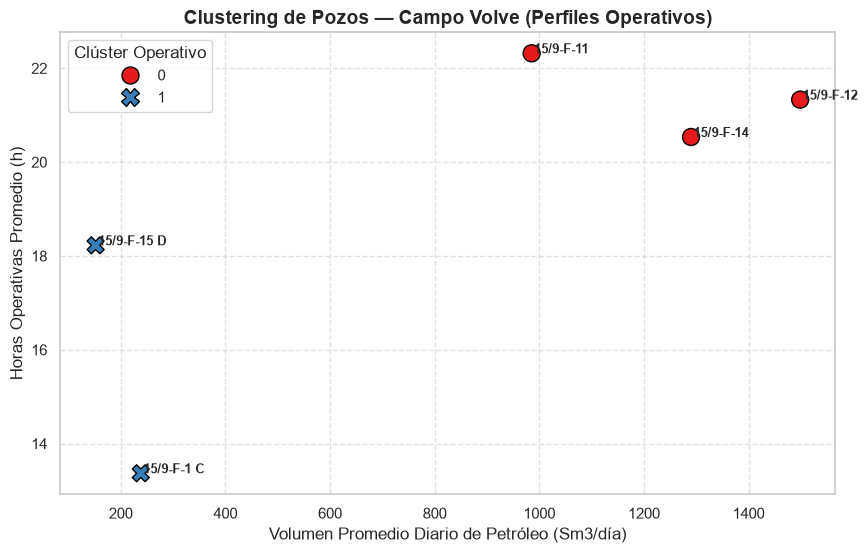

In [6]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=perfil_pozos,
    x="oil_vol_mean",
    y="horas_operativas_mean",
    hue="Cluster",
    palette="Set1",
    s=150,
    style="Cluster",
    edgecolor="black"
)

# Anotar los nombres de los pozos en el gráfico
for idx, row in perfil_pozos.iterrows():
    plt.annotate(
        row["NPD_WELL_BORE_NAME"],
        (row["oil_vol_mean"] + 5, row["horas_operativas_mean"]),
        fontsize=9,
        weight="bold"
    )

plt.title("Clustering de Pozos — Campo Volve (Perfiles Operativos)", fontsize=14, weight="bold")
plt.xlabel("Volumen Promedio Diario de Petróleo (Sm3/día)")
plt.ylabel("Horas Operativas Promedio (h)")
plt.legend(title="Clúster Operativo")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

### 6. Conclusiones del Clustering
* **Criterio de agrupación:** El algoritmo permitió separar de forma objetiva los pozos con alta tasa de producción sostenida de aquellos con mayores restricciones operativas o declinación avanzada.
* **Aplicación industrial:** Esta segmentación no supervisada resulta clave para priorizar campañas de optimización (como intervenciones de *Workover*, ajuste de diámetro de estrangulador o control de producción de agua) agrupando activos con dinámicas físicas similares.